# ML Model with expected goals

In [8]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import warnings
from sklearn.linear_model import LinearRegression

NUM_OF_COUNTRIES = 5
NUM_OF_SEASONS = 25
NUM_OF_MATCHES = 9130
NUM_OF_MATCHES_IN_A_SEASON = 1826
SEED = 1893

np.random.seed(SEED)
warnings.filterwarnings('ignore')


In [9]:
def score_from_amount_and_diff(amount, diff):
    if diff < 0:
        home_score = (amount + diff) / 2
        away_score = home_score - diff
    else:
        away_score = (amount - diff) / 2
        home_score = away_score + diff

    # cut excess floating numbers
    if (home_score - int(home_score)) == 0 and (away_score - int(away_score)) == 0:
        home_score = int(home_score)
        away_score = int(away_score)

    return home_score, away_score


def print_formatted_pred_score(country, season, matchnumber, ht_name, at_name, ht_pred_score, at_pred_score, ht_actual_score, at_actual_score):
    print("%4s %3s %3s %20s %20s %15s | %6s" %
          (country, season, matchnumber, ht_name, at_name,
           str(ht_pred_score)[0:4] + ":" + str(at_pred_score)[0:4],
           f"{ht_actual_score}:{at_actual_score}"))

def calc_mae(y_pred, y):
    mae = 0.0
    for pred, actual_value in zip(y_pred, y):
        if type(pred) == list:
            mae += np.abs((float(pred[0]) - float(actual_value)))
        else:
            mae += np.abs((float(pred) - float(actual_value)))
    return mae / len(y)


In [10]:
df_matches = pd.read_csv('matches_xg.csv', sep=';')

df_matches["is_eng"] = df_matches["country"].apply(
    lambda x: 1 if x == "ENG" else 0)
df_matches["is_esp"] = df_matches["country"].apply(
    lambda x: 1 if x == "ESP" else 0)
df_matches["is_fra"] = df_matches["country"].apply(
    lambda x: 1 if x == "FRA" else 0)
df_matches["is_ger"] = df_matches["country"].apply(
    lambda x: 1 if x == "GER" else 0)
df_matches["is_ita"] = df_matches["country"].apply(
    lambda x: 1 if x == "ITA" else 0)

all_features = [
    "ht_curr_eff_chancediff", "at_curr_eff_chancediff",
    "ht_past_chancediff_combined", "at_past_chancediff_combined",
    "ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
    "ht_past_chanceamount", "at_past_chanceamount",
    "ht_fitness", "at_fitness",
    "ht_market_value_ln_relative", "at_market_value_ln_relative",
    "ht_curr_chancediff", "at_curr_chancediff",
    "ht_last_year_chancediff", "at_last_year_chancediff",
    "ht_curr_chanceamount", "at_curr_chanceamount",
    "ht_last_year_chanceamount", "at_last_year_chanceamount",
    "ht_market_value", "at_market_value",
    "ht_market_value_ln", "at_market_value_ln",
    "is_eng", "is_esp", "is_fra", "is_ger", "is_ita"
]

ga_best_features = [
    "ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
    "ht_past_chanceamount", "at_past_chanceamount",
    "is_eng", "is_esp", "is_fra", "is_ger", "is_ita"
]

gd_best_features = [
    "ht_curr_eff_chancediff", "at_curr_eff_chancediff",
    "ht_last_year_chancediff", "at_last_year_chancediff",
    "ht_market_value_ln_relative", "at_market_value_ln_relative",
    "is_eng", "is_esp", "is_fra", "is_ger", "is_ita"
]

ga_feature_set_heuer_country = [
    "ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
    "ht_past_chanceamount", "at_past_chanceamount",
    "is_eng", "is_esp", "is_fra", "is_ger", "is_ita"
]

gd_feature_set_heuer_country = [
    "ht_curr_eff_chancediff", "at_curr_eff_chancediff",
    "ht_past_chancediff_combined", "at_past_chancediff_combined",
    "ht_fitness", "at_fitness",
    "ht_market_value_ln_relative", "at_market_value_ln_relative",
    "is_eng", "is_esp", "is_fra", "is_ger", "is_ita"
]

ga_feature_set_heuer = [
    "ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
    "ht_past_chanceamount", "at_past_chanceamount"
]

gd_feature_set_heuer = [
    "ht_curr_eff_chancediff", "at_curr_eff_chancediff",
    "ht_past_chancediff_combined", "at_past_chancediff_combined",
    "ht_fitness", "at_fitness",
    "ht_market_value_ln_relative", "at_market_value_ln_relative"
]


ga_label = ["xg_amount"]
gd_label = ["xg_diff"]

ga_test_label = ["actual_goalamount"]
gd_test_label = ["actual_goaldiff"]

df_matches


,country,season,matchnumber,ht_name,at_name,ht_curr_eff_chancediff,at_curr_eff_chancediff,ht_past_chancediff_combined,at_past_chancediff_combined,ht_curr_eff_chanceamount,...,at_market_value_ln,xg_amount,xg_diff,actual_goalamount,actual_goaldiff,is_eng,is_esp,is_fra,is_ger,is_ita
0,ENG,14,1,Queens Park Rangers,Hull,0.000000,0.000000,0.000000,0.000000,0.000000,...,18.577684,3.018240,0.783100,1,-1,1,0,0,0,0
1,ENG,14,1,Newcastle,Man City,0.000000,0.000000,0.000000,0.000000,0.000000,...,19.929193,2.446113,-0.514947,2,-2,1,0,0,0,0
2,ENG,14,1,Burnley,Chelsea,0.000000,0.000000,0.000000,0.000000,0.000000,...,20.138076,2.501101,-1.758819,4,-2,1,0,0,0,0
3,ENG,14,1,Arsenal,Crystal Palace,0.000000,0.000000,0.000000,0.000000,0.000000,...,18.390222,1.712261,1.395959,3,1,1,0,0,0,0
4,ENG,14,1,West Ham,Tottenham,0.000000,0.000000,0.000000,0.000000,0.000000,...,19.532538,2.870160,0.836040,1,-1,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9125,ITA,18,38,Frosinone,Chievo,-4.492426,-4.452152,-3.581579,-1.943421,-2.059192,...,17.822844,0.585014,0.537046,0,0,0,0,0,0,1
9126,ITA,18,38,Fiorentina,CFC Genoa,1.172165,-1.286395,1.539474,-1.361842,0.407509,...,19.073006,0.370430,0.221648,0,0,0,0,0,0,1
9127,ITA,18,38,Bologna,Napoli,-0.932129,5.242267,-1.497368,5.293421,-0.446689,...,20.287857,2.737759,-0.858041,5,1,0,0,0,0,1
9128,ITA,18,38,Inter,Empoli,2.881676,-3.462648,2.380263,-3.058772,1.042860,...,18.478950,4.515770,0.970270,3,1,0,0,0,0,1


## Data split

In [11]:
df_training, df_testing = df_matches.query(
    f"season < 18"), df_matches.query(f"season == 18")


## Remove outliers

In [12]:
df_training_cleansed_classic = df_training.query(
    "actual_goalamount <= 8 and actual_goaldiff <= 6").copy()

df_training["a_x_ga"] = df_training.apply(lambda x: np.abs(
    float(x["actual_goalamount"]) - x["xg_amount"]),axis=1)
df_training["a_x_gd"] = df_training.apply(lambda x: np.abs(
    float(x["actual_goaldiff"]) - x["xg_diff"]), axis=1)

df_training_cleansed_a_x = df_training.query(
    "a_x_ga <= 5 and a_x_gd <= 5").copy()

print(df_training_cleansed_classic.shape)
print(df_training_cleansed_a_x.shape)


(7274, 40)
(7281, 42)


## Model selection

In [13]:
class GeneralModel:
    def __init__(self):
        self.model = LinearRegression() 

    def fit(self, df, features, label):
        self.model.fit(df[features], df[label])

    def predict(self, df, features):
        return self.model.predict(df[features])

    def predict_single(self, row, features):
        return self.model.predict([row[features]])[0][0]


class WeightsPerMatchnumberModel:
    def __init__(self):
        self.models = []

    def fit(self, df, features, label):
        for i in range(1, 39):
            matchnumber_df = df.query(f"matchnumber == {i}")
            self.models.append(LinearRegression().fit(matchnumber_df[features],
                               matchnumber_df[label]))

    def predict(self, df, features):
        preds = []
        for index, row in df.iterrows():
            preds.append(
                self.models[row["matchnumber"]-1].predict([row[features]])[0])
        return preds

    def predict_single(self, row, features):
        return self.models[row["matchnumber"]-1].predict([row[features]])[0]


class SectionedModel:
    def __init__(self):
        self.models = [LinearRegression(), LinearRegression(),
                       LinearRegression()]

    def fit(self, df, features, label):
        first_df = df.query(f"(country == 'GER' and matchnumber < 18) or (country != 'GER' and matchnumber < 20)")
        second_df = df.query(
            f"(country == 'GER' and matchnumber >= 18 and matchnumber < 31) or (country != 'GER' and matchnumber >= 20 and matchnumber < 35)")
        third_df = df.query(
            f"(country == 'GER' and matchnumber >= 31) or (country != 'GER' and matchnumber >= 35)")
        if not first_df.empty:
            self.models[0].fit(first_df[features], first_df[label])
        else:
            self.models[0].fit([np.ones(len(features))], [[1]])
        if not second_df.empty:
            self.models[1].fit(second_df[features], second_df[label])
        else:
            self.models[1].fit([np.ones(len(features))], [[1]])
        if not third_df.empty:
            self.models[2].fit(third_df[features], third_df[label])
        else:
            self.models[2].fit([np.ones(len(features))], [[1]])
        

    def predict(self, df, features):
        preds = []
        for index, row in df.iterrows():
            if (row["country"] == "GER" and row["matchnumber"] < 18) or (row["country"] != 'GER' and row["matchnumber"] < 20):
                preds.append(self.models[0].predict([row[features]])[0])
            if (row["country"] == "GER" and row["matchnumber"] >= 18) and (row["matchnumber"] < 31) or (row["country"] != 'GER' and row["matchnumber"] >= 20 and row["matchnumber"] < 35):
                preds.append(self.models[1].predict([row[features]])[0])
            if (row["country"] == "GER" and row["matchnumber"] >= 31) or (row["country"] != 'GER' and row["matchnumber"] >= 35):
                preds.append(self.models[2].predict([row[features]])[0])
        return preds

    def predict_single(self, row, features):
        if (row["country"] == "GER" and row["matchnumber"] < 18) or (row["country"] != 'GER' and row["matchnumber"] < 20):
            return self.models[0].predict([row[features]])[0][0]
        if (row["country"] == "GER" and row["matchnumber"] >= 18) and (row["matchnumber"] < 31) or (row["country"] != 'GER' and row["matchnumber"] >= 20 and row["matchnumber"] < 35):
            return self.models[1].predict([row[features]])[0][0]
        if (row["country"] == "GER" and row["matchnumber"] >= 31) or (row["country"] != 'GER' and row["matchnumber"] >= 35):
            return self.models[2].predict([row[features]])[0][0]


## K-Fold-Crossvalidation

In [14]:
# Validate over:
# Feature selection (3)
# general weights; weights per matchnumber; weights for first seasonhalf, second and last 4
# Train-Valid split per season (4)
do_crossvalidation = False

if do_crossvalidation:
    for data_name, train_df in zip(["full", "cleansed_classic", "cleansed_a_x"], [df_training, df_training_cleansed_classic, df_training_cleansed_a_x]):
        for feature_set_name, feature_set in zip(["all", "heuer", "heuer_country", "selection"],[(all_features, all_features), (ga_feature_set_heuer, gd_feature_set_heuer), (ga_feature_set_heuer_country, gd_feature_set_heuer_country), (ga_best_features, gd_best_features)]):
            for weight_set_name in ["general", "per_match_no", "sectioned"]:
                ga_validation_error, gd_validation_error = 0, 0
                for season in range(14,18):
                    train_data, valid_data = train_df.query(
                        f"season != {season}"), train_df.query(f"season == {season}")

                    if weight_set_name == "general":
                        ga_model, gd_model = GeneralModel(), GeneralModel()
                        ga_model.fit(
                            train_data, feature_set[0], ga_label)
                        gd_model.fit(
                            train_data, feature_set[1], gd_label)
                    if weight_set_name == "per_match_no":
                        ga_model, gd_model = WeightsPerMatchnumberModel(), WeightsPerMatchnumberModel()
                        ga_model.fit(
                            train_data, feature_set[0], ga_label)
                        gd_model.fit(
                            train_data, feature_set[1], gd_label)
                    if weight_set_name == "sectioned":
                        ga_model, gd_model = SectionedModel(), SectionedModel()
                        ga_model.fit(
                            train_data, feature_set[0], ga_label)
                        gd_model.fit(
                            train_data, feature_set[1], gd_label)
                    
                    ga_validation_error += (calc_mae(ga_model.predict(
                        valid_data, feature_set[0]), valid_data[ga_label].values)) * 0.25
                    gd_validation_error += (calc_mae(gd_model.predict(
                        valid_data, feature_set[1]), valid_data[gd_label].values)) * 0.25

                print("%-8s %-16s %-12s " %
                    (data_name, feature_set_name, weight_set_name))
                print("xga validation error:", ga_validation_error)
                print("xgd validation error:", gd_validation_error, end="\n\n")

# cleansed_classic  selection   sectioned
# xga validation error: 0.8698765542571665

# cleansed_classic  selection   sectioned    
# xgd validation error: 0.8115073782517024


full     all              general      
xga validation error: 1.0064249748670213
xgd validation error: 0.8236016683041462

full     all              per_match_no 
xga validation error: 1.1873107344555656
xgd validation error: 1.2169294813715021

full     all              sectioned    
xga validation error: 0.962948316306924
xgd validation error: 0.8362223045173393

full     heuer            general      
xga validation error: 0.8944589580708002
xgd validation error: 0.8150468303121332

full     heuer            per_match_no 
xga validation error: 0.9501422669926428
xgd validation error: 0.8472196372323754

full     heuer            sectioned    
xga validation error: 0.8928498823207045
xgd validation error: 0.8141847088450261

full     heuer_country    general      
xga validation error: 0.8767476084112654
xgd validation error: 0.8149418478243021

full     heuer_country    per_match_no 
xga validation error: 0.949184837783595
xgd validation error: 0.8610608827230584

full     heuer_cou

## Final models

In [41]:
ga_model = SectionedModel()
gd_model = SectionedModel()

ga_model.fit(df_training_cleansed_classic, ga_best_features, ga_label)
gd_model.fit(df_training_cleansed_classic, gd_best_features, gd_label)

print("Generalizazion error xga:", calc_mae(ga_model.predict(
    df_testing, ga_best_features), df_testing[ga_label].values))
print("Generalizazion error xgd:", calc_mae(gd_model.predict(
    df_testing, gd_best_features), df_testing[gd_label].values))
print("------")
print("Generalizazion error ga :", calc_mae(ga_model.predict(
    df_testing, ga_best_features), df_testing[ga_test_label].values))
print("Generalizazion error gd :", calc_mae(gd_model.predict(
    df_testing, gd_best_features), df_testing[gd_test_label].values))


Generalizazion error xga: 0.8417027511034276
Generalizazion error xgd: 0.8497166072224509
------
Generalizazion error ga : 1.318776409906297
Generalizazion error gd : 1.2362692494934615


## Generate training error csv

In [59]:
do_a_training_error_run = False

if do_a_training_error_run:
      training_error_data = dict()
      xga_abs_training_error, xgd_abs_training_error = 0,0
      ga_abs_training_error, gd_abs_training_error = 0,0
      prev_matchnumber = 0

      for index, row in df_training_cleansed_classic.iterrows():
            if row["season"] == 14 and row["matchnumber"] == 1:
                  ga_pred, gd_pred = 0,0
            else:
                  if int(row["matchnumber"]) > prev_matchnumber:
                        curr_training_data_df = df_training_cleansed_classic.query(
                            f"season < {row['season']} or (season == {row['season']} and matchnumber < {row['matchnumber']})")
                        ga_model = SectionedModel()
                        gd_model = SectionedModel()
                        ga_model.fit(curr_training_data_df,
                                     ga_best_features, ga_label)
                        gd_model.fit(curr_training_data_df,
                                     gd_best_features, gd_label)

                  ga_pred = ga_model.predict_single(
                      row, ga_best_features)
                  gd_pred = gd_model.predict_single(
                      row, gd_best_features)

            xga_abs_training_error += np.abs(
                  ga_pred - float(row[ga_label]))
            xgd_abs_training_error += np.abs(
                gd_pred - float(row[gd_label]))
            ga_abs_training_error += np.abs(
                ga_pred - float(row[ga_test_label]))
            gd_abs_training_error += np.abs(
                gd_pred - float(row[gd_test_label]))
            
            if row["country"] not in training_error_data.keys():
                  training_error_data[row["country"]] = {}
            if row["season"] not in training_error_data[row["country"]].keys():
                  training_error_data[row["country"]][row["season"]] = {}
            if row["matchnumber"] not in training_error_data[row["country"]][row["season"]].keys():
                  training_error_data[row["country"]
                                          ][row["season"]][row["matchnumber"]] = {"abs_error_ga": 0, "abs_error_gd": 0, "abs_error_xga": 0, "abs_error_xgd": 0}
            if row["country"] == "GER":
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_ga"] += float(np.abs(ga_pred - row[ga_test_label]) / 9)
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_gd"] += float(np.abs(gd_pred - row[gd_test_label]) / 9)
                  training_error_data[row["country"]
                                          ][row["season"]][row["matchnumber"]]["abs_error_xga"] += float(np.abs(ga_pred - row[ga_label]) / 9)
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_xgd"] += float(np.abs(gd_pred - row[gd_label]) / 9)
            else:
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_ga"] += float(np.abs(ga_pred - row[ga_test_label]) / 10)
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_gd"] += float(np.abs(gd_pred - row[gd_test_label]) / 10)
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_xga"] += float(np.abs(ga_pred - row[ga_label]) / 10)
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_xgd"] += float(np.abs(gd_pred - row[gd_label]) / 10)

      print("Training MAE xga:",
            xga_abs_training_error / (NUM_OF_MATCHES_IN_A_SEASON*4))
      print("Training MAE xgd:", xgd_abs_training_error /
            (NUM_OF_MATCHES_IN_A_SEASON*4))
      print("Training MAE ga :",
            ga_abs_training_error / (NUM_OF_MATCHES_IN_A_SEASON*4))
      print("Training MAE gd :", gd_abs_training_error /
            (NUM_OF_MATCHES_IN_A_SEASON*4))


Training MAE xga: 0.8162855531536217
Training MAE xgd: 0.8139363772405622
Training MAE ga : 1.3129126368933908
Training MAE gd : 1.2342485982424518


In [60]:
if do_a_training_error_run:
      print("country;season_matchnumber;abs_error_ga;abs_error_gd;abs_error_xga;abs_error_xgd")
      for a in training_error_data.keys():
            for b in training_error_data[a].keys():
                  for c in training_error_data[a][b].keys():
                        print(a+";"+str(b)+"_"+str(c)+";" +
                              str(training_error_data[a][b][c]["abs_error_ga"])+";"+str(training_error_data[a][b][c]["abs_error_gd"])+";" +
                              str(training_error_data[a][b][c]["abs_error_xga"])+";"+str(training_error_data[a][b][c]["abs_error_xgd"]))


country;season_matchnumber;abs_error_ga;abs_error_gd;abs_error_xga;abs_error_xgd
ENG;14_1;2.6;0.9999999999999999;2.2776747;0.8240660999999999
ENG;14_2;1.3592654653061222;1.007071037129702;0.5808675653061224;0.536879481136582
ENG;14_3;1.266633090067932;1.3419337452447273;0.7224686572983826;0.7263633074704099
ENG;14_4;1.735138461723957;1.4081627272802704;0.9264256501144363;0.7627958170760624
ENG;14_5;1.9203598376993365;1.3225287841301203;0.8812235714269038;0.6684261201207556
ENG;14_6;1.1829692814716863;1.0593455901736626;0.466450903386227;0.85397949263407
ENG;14_7;0.9218137269014053;0.8981927293409404;0.58302355135147;0.6203895021032755
ENG;14_8;1.2958739046290426;0.9833157915564836;1.1574183292411981;0.6724563028613515
ENG;14_9;1.0135462041115868;1.0687365228175385;0.7152651935856329;0.6084616721890843
ENG;14_10;1.3479384425034149;0.9621359454493491;0.8629897142881466;1.1514728442688802
ENG;14_11;0.9549903120363924;1.0004471534908737;0.6246890075694981;0.7585963197767684
ENG;14_12;0.865

## Plot training error

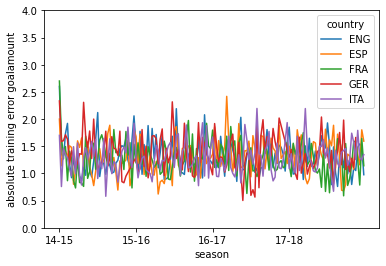

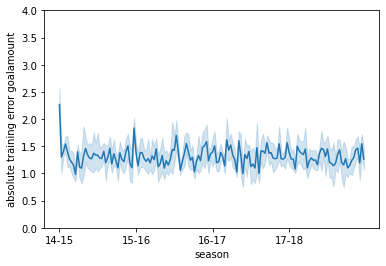

In [63]:
training_error_df = pd.read_csv('training_error.csv', sep=';')
sns.lineplot(data=training_error_df,
             x="season_matchnumber", y="abs_error_ga", hue="country")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 4)
plt.xlabel("season")
plt.ylabel("absolute training error goalamount")
plt.show()
sns.lineplot(data=training_error_df, x="season_matchnumber",
             y="abs_error_ga")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 4)
plt.xlabel("season")
plt.ylabel("absolute training error goalamount")
plt.show()


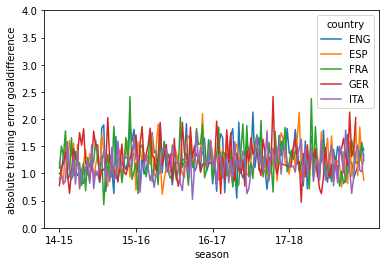

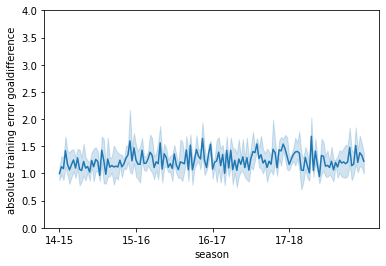

In [64]:
sns.lineplot(data=training_error_df, x="season_matchnumber",
             y="abs_error_gd", hue="country")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 4)
plt.xlabel("season")
plt.ylabel("absolute training error goaldifference")
plt.show()
sns.lineplot(data=training_error_df, x="season_matchnumber",
             y="abs_error_gd")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 4)
plt.xlabel("season")
plt.ylabel("absolute training error goaldifference")
plt.show()


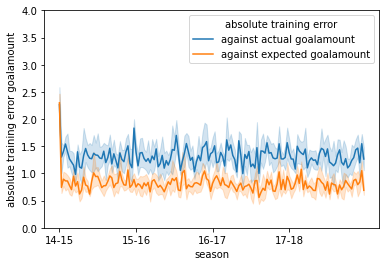

In [67]:
training_error_df["against actual goalamount"] = training_error_df["abs_error_ga"]
training_error_df["against expected goalamount"] = training_error_df["abs_error_xga"]
melted_df = training_error_df[["season_matchnumber", "against actual goalamount", "against expected goalamount"]].melt(
    "season_matchnumber", var_name="absolute training error", value_name="vals")

sns.lineplot(data=melted_df, x="season_matchnumber",
             y="vals", hue="absolute training error")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.xlabel("season")
plt.ylabel("absolute training error goalamount")
plt.ylim(0, 4)
plt.show()


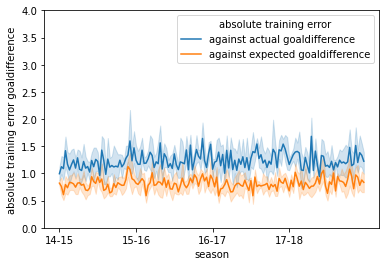

In [66]:
training_error_df["against actual goaldifference"] = training_error_df["abs_error_gd"]
training_error_df["against expected goaldifference"] = training_error_df["abs_error_xgd"]
melted_df = training_error_df[["season_matchnumber", "against actual goaldifference", "against expected goaldifference"]].melt(
    "season_matchnumber", var_name="absolute training error", value_name="vals")

sns.lineplot(data=melted_df, x="season_matchnumber",
             y="vals", hue="absolute training error")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.xlabel("season")
plt.ylabel("absolute training error goaldifference")
plt.ylim(0, 4)
plt.show()
